# Carteras de bajo incumplimiento: la estimación más prudente de Pluto y Tasche

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 02 de este tema (intervalos en un grado delgado)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar la estimación más prudente: una PD para cada grado como cota superior de confianza, bajo el supuesto de que todo grado peor tiene la misma PD, y decir por qué necesita conteos agrupados;
- calcular la cota para incumplimientos independientes y verificarla contra la forma cerrada para cero incumplimientos y contra el cuantil Beta de SciPy;
- agregar correlación de incumplimientos con el modelo de un factor, y leer cuánto sube la cota;
- escalar las cotas a una meta de la cartera, y llevar una cohorte de varios años con factores con correlación serial;
- recalcular las 204 celdas impresas de las Tablas 1 a 14 de Pluto y Tasche, listar las celdas que se desvían y decir por qué;
- leer lo que dice el estudio de verdad conocida versionado sobre la cobertura, y cuánto cuestan las cotas en capital.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import low_default as ld
from riskvalidation.regulatory import capital_requirement
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro archivos versionados del caso C05, la segunda mitad del caso: carteras de bajo incumplimiento (clase de licencia `derived-only` para las tablas impresas de Pluto y Tasche, 2005; https://arxiv.org/abs/cond-mat/0411699):

- `data/derived/C05/ldp-published.json`: el ejemplo del artículo, tres grados A, B y C con 100, 400 y 300 deudores y 0, 2 y 1 incumplimientos, las cotas a seis niveles de confianza, las 204 celdas impresas de las Tablas 1 a 14 con el recálculo (`outputs.golden`), las pruebas versionadas de las PD de un experto hipotético, y el impacto en capital.
- `data/derived/C05/ldp-sim-0.json`, `ldp-sim-1.json` y `ldp-sim-3.json`: la misma cartera en un año generado por un modelo de Vasicek con PD conocidas (0,05%, 0,10% y 0,20%, correlación 12%) con ningún incumplimiento, uno y tres, cada uno con la cobertura de las cotas y el tamaño y la potencia de las pruebas medidos en 20.000 años generados.

Los conteos por grado son el ejemplo del propio artículo, público en él. La celda siguiente carga los archivos e imprime lo que contienen.

In [2]:
# Cargar los cuatro artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir el ejemplo
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
published = load("ldp-published.json")
sims = {k: load(f"ldp-sim-{k}.json") for k in (0, 1, 3)}
out = published["outputs"]
grades, N, few = out["grades"], tuple(out["obligors"]), tuple(out["defaults"])
gammas, rho = out["gammas"], out["rho"]

for label, doc in [("ldp-published", published)] + [(f"ldp-sim-{k}", d) for k, d in sims.items()]:
    print(f"{label:14s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("grados:", grades, "| deudores:", N, "| incumplimientos:", few)
print("niveles de confianza:", gammas, "| correlación de activos del artículo:", rho)
print("PD expertas hipotéticas:", out["expert_pd"])

ldp-published  calculado con riskvalidation 0.4.3 | instalado 0.9.0
ldp-sim-0      calculado con riskvalidation 0.4.3 | instalado 0.9.0
ldp-sim-1      calculado con riskvalidation 0.4.3 | instalado 0.9.0
ldp-sim-3      calculado con riskvalidation 0.4.3 | instalado 0.9.0
grados: ['A', 'B', 'C'] | deudores: (100, 400, 300) | incumplimientos: (0, 2, 1)
niveles de confianza: [0.5, 0.75, 0.9, 0.95, 0.99, 0.999] | correlación de activos del artículo: 0.12
PD expertas hipotéticas: [0.0003, 0.0005, 0.001]


## Método

### Paso 1: la estimación más prudente, incumplimientos independientes

Con tres incumplimientos en 800 deudores una cartera tiene una tasa de incumplimiento, pero los grados individuales no: A no tiene ninguno. Pluto y Tasche (2005) piden la PD de cada grado como **cota superior de confianza** al nivel $\gamma$, bajo el supuesto *más prudente* compatible con el orden de los grados: todo grado desde $i$ hacia abajo tiene la misma PD, así que se agrupan los deudores y los incumplimientos de los grados $i, \dots, k$. Con $N$ deudores agrupados y $D$ incumplimientos agrupados, incumplimientos independientes, la cota $p$ resuelve

$$P\bigl(\mathrm{Binomial}(N, p) \le D\bigr) = 1 - \gamma$$

(la cota superior de Clopper-Pearson). Para $D = 0$ tiene la forma cerrada $p = 1 - (1 - \gamma)^{1/N}$. El `most_prudent_pd` del motor devuelve las cotas y los conteos agrupados. Hay dos verificaciones independientes: la forma cerrada para un caso sin incumplimientos, y el cuantil de la distribución Beta de SciPy, pues la cola binomial y la función de distribución Beta son la misma función. La celda imprime los conteos agrupados, las cotas al 90%, las verificaciones y la comparación con las cotas versionadas.

In [3]:
# Las cotas más prudentes del ejemplo al 90%, la forma cerrada para cero incumplimientos, el cuantil Beta de SciPy y las cotas versionadas
gamma = 0.9
r = ld.most_prudent_pd(N, few, gamma)
print("deudores agrupados (grado i hasta el peor):", r["pooled_obligors"], "| incumplimientos agrupados:", r["pooled_defaults"])
beta_check = [stats.beta.ppf(gamma, d + 1, n - d) for n, d in zip(r["pooled_obligors"], r["pooled_defaults"])]
print(f"{'grado':8s}{'cota al 90% (%)':>26s}{'cuantil Beta (%)':>26s}")
for g, p, b in zip(grades, r["pd"], beta_check):
    print(f"{g:8s}{100 * p:26.4f}{100 * b:26.4f}")
print("igual al cuantil Beta:", si_no(np.allclose(r["pd"], beta_check, atol=1e-12)))

zero = ld.most_prudent_pd(N, (0, 0, 0), gamma)
closed = [1 - (1 - gamma) ** (1 / n) for n in zero["pooled_obligors"]]
print("cero incumplimientos: motor", [round(100 * p, 4) for p in zero["pd"]], "| forma cerrada", [round(100 * p, 4) for p in closed], "| igual:", si_no(np.allclose(zero["pd"], closed, atol=1e-12)))
committed = np.array(out["bounds"]["independent"])
print("igual a las cotas versionadas, seis niveles:", si_no(np.allclose([ld.most_prudent_pd(N, few, g)["pd"] for g in gammas], committed, atol=1e-9)))

deudores agrupados (grado i hasta el peor): [800, 700, 300] | incumplimientos agrupados: [3, 3, 1]
grado              cota al 90% (%)          cuantil Beta (%)
A                           0.8332                    0.8332
B                           0.9519                    0.9519
C                           1.2903                    1.2903
igual al cuantil Beta: sí
cero incumplimientos: motor [0.2874, 0.3284, 0.7646] | forma cerrada [0.2874, 0.3284, 0.7646] | igual: sí
igual a las cotas versionadas, seis niveles: sí


Las cotas suben de A a C, como lo garantiza la construcción, y todo grado, incluso A sin incumplimientos, recibe una PD positiva que descansa en los 800 deudores. El costo es el conservadurismo: las cotas dicen qué tan alta puede ser la PD con esa confianza, no cuál es probablemente.

### Paso 2: correlación de incumplimientos

Los incumplimientos de deudores que comparten una economía están correlacionados, y la ley binomial subestima entonces la dispersión del número de incumplimientos. Pluto y Tasche (sección 4) usan el modelo de un factor: cada deudor cae en incumplimiento cuando $\sqrt{\rho}\,Y + \sqrt{1-\rho}\,\xi$ queda bajo $\Phi^{-1}(p)$, con un factor común $Y$, así que dado $Y = y$ la probabilidad de incumplimiento es $p(y) = \Phi\bigl((\Phi^{-1}(p) - \sqrt{\rho}\,y)/\sqrt{1-\rho}\bigr)$ y la cota resuelve

$$1 - \gamma = \int \varphi(y)\, P\bigl(\mathrm{Binomial}(N, p(y)) \le D\bigr)\, dy$$

El motor integra por cuadratura de Gauss-Hermite. El artículo toma $\rho = 12\%$, la correlación corporativa mínima de Basilea (CRE31). La celda siguiente calcula las cotas correlacionadas a los seis niveles, las compara con las versionadas e imprime cuántas veces más altas son que las independientes.

In [4]:
# Las cotas correlacionadas a los seis niveles, contra las versionadas y contra las cotas independientes
correlated = np.array([ld.most_prudent_pd(N, few, g, rho)["pd"] for g in gammas])
independent = np.array([ld.most_prudent_pd(N, few, g)["pd"] for g in gammas])
print("igual a las cotas correlacionadas versionadas:", si_no(np.allclose(correlated, out["bounds"]["correlated"], atol=1e-9)))
print(f"{'gamma':>7s}" + "".join(f"{g + ' (%)':>12s}" for g in grades) + "".join(f"{g + ' razón':>12s}" for g in grades))
for gm, c, i in zip(gammas, correlated, independent):
    print(f"{gm:7.3f}" + "".join(f"{100 * v:12.4f}" for v in c) + "".join(f"{v:12.2f}" for v in c / i))

igual a las cotas correlacionadas versionadas: sí
  gamma       A (%)       B (%)       C (%)     A razón     B razón     C razón
  0.500      0.7106      0.8006      0.8352        1.55        1.53        1.49
  0.750      1.4149      1.5808      1.7536        2.22        2.17        1.96
  0.900      2.4910      2.7617      3.1813        2.99        2.90        2.47
  0.950      3.4121      3.7653      4.4078        3.53        3.41        2.80
  0.990      5.8758      6.4272      7.6714        4.70        4.50        3.50
  0.999     10.0754     10.9121     13.1333        6.21        5.89        4.33


### Paso 3: escalar a una meta de la cartera

Las cotas de los tres grados son todas cotas superiores: su promedio ponderado queda muy por sobre la tasa de incumplimiento propia de la cartera. La sección 5 del artículo las escala con un factor común $K$, manteniendo su orden y sus razones, de modo que el promedio ponderado por deudores iguale una meta $T$:

$$K = \frac{T \sum_i n_i}{\sum_i n_i\, \hat p_i}, \qquad p_i^{\mathrm{escalada}} = K\, \hat p_i$$

(ecuaciones 5.1 y 5.2). Se usan dos metas: la tasa de incumplimiento observada de la cartera (la *tendencia central*, necesita al menos un incumplimiento) y la cota más prudente de toda la cartera, que es la cota del mejor grado (la *cota superior*, la propuesta del artículo). Escalar renuncia a leer los números como cotas de confianza. La celda llama a `most_prudent_pd_scaled` para ambas metas al 90%, verifica que el promedio ponderado iguala la meta y compara con las filas versionadas.

In [5]:
# Escalar las cotas al 90% a las dos metas, verificar el promedio ponderado y comparar con las filas versionadas
level = 2                                                 # índice del 90% en los seis niveles
n_array = np.array(N, dtype=float)
for target, key in (("upper_bound", "scaled_upper_bound"), ("central_tendency", "scaled_central_tendency")):
    s = ld.most_prudent_pd_scaled(N, few, 0.9, target=target)
    row = out["bounds"][key][level]
    label = {"upper_bound": "cota superior", "central_tendency": "tendencia central"}[target]
    print(f"{label:20s} T = {s['target']:.6f} | K = {s['k']:.6f} | PD escaladas (%)", [round(100 * v, 4) for v in s["pd"]])
    print(f"{'':20s} el promedio ponderado iguala T:", si_no(np.isclose(np.sum(n_array * s['pd']) / n_array.sum(), s['target'])),
          "| orden mantenido:", si_no(np.all(np.diff(s['pd']) > 0)),
          "| igual a la fila versionada:", si_no(np.allclose(s["pd"], row["pd"], atol=1e-9) and np.isclose(s["k"], row["k"])))
print("cotas al 90% sin escalar, como referencia:", [round(100 * v, 4) for v in ld.most_prudent_pd(N, few, 0.9)["pd"]])

cota superior        T = 0.008332 | K = 0.783083 | PD escaladas (%) [0.6524, 0.7454, 1.0104]
                     el promedio ponderado iguala T: sí | orden mantenido: sí | igual a la fila versionada: sí
tendencia central    T = 0.003750 | K = 0.352453 | PD escaladas (%) [0.2937, 0.3355, 0.4548]
                     el promedio ponderado iguala T: sí | orden mantenido: sí | igual a la fila versionada: sí
cotas al 90% sin escalar, como referencia: [0.8332, 0.9519, 1.2903]


Las cotas escaladas quedan entre la tasa de incumplimiento de la cartera y las cotas crudas: el factor común K es menor que uno para ambas metas aquí.

### Paso 4: una cohorte seguida varios años

Con una cohorte observada $T$ años los incumplimientos son los de todo el período, y el factor de cada año se correlaciona con el siguiente. La sección 6 del artículo toma factores normales estándar $S_t$ con correlación $\theta^{|s-t|}$; el deudor cae en incumplimiento en el año $t$ cuando $\sqrt{\rho}\,S_t + \sqrt{1-\rho}\,\xi_{it}$ queda por primera vez bajo $\Phi^{-1}(p)$, así que $p$ es una PD a un año de largo plazo. Dados los factores un deudor cae en incumplimiento dentro del período con probabilidad $1 - \prod_t (1 - p(S_t))$ (6.7), y la cota es la mayor $p$ con $P[\text{a lo más } D \text{ incumplimientos}] \ge 1 - \gamma$ (6.6, 6.8b). La esperanza sobre los factores es un promedio Monte Carlo, con las mismas trayectorias para todo $p$. La celda usa el ajuste del artículo ($\rho = 12\%$, $\theta = 30\%$, cinco años) con 100.000 trayectorias y semilla 5, el ajuste de la corrida versionada, para el ejemplo y para la misma cartera sin incumplimientos.

In [6]:
# Cotas de varios períodos al 90% y 99% para el ejemplo y para cero incumplimientos, frente a las cotas de un año
settings = dict(rho=0.12, theta=0.3, years=5, n_sim=100_000, seed=5)
print("ajustes:", settings)
print(f"{'':26s}" + "".join(f"{g:>10s}" for g in grades))
for gm in (0.9, 0.99):
    for label, d in (("ejemplo", few), ("sin incumplimientos", (0, 0, 0))):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        one = ld.most_prudent_pd(N, d, gm)["pd"]
        print(f"{label + ' ' + str(gm) + ' 5y (%)':26s}" + "".join(f"{100 * v:10.4f}" for v in multi))
        print(f"{label + ' ' + str(gm) + ' 1y (%)':26s}" + "".join(f"{100 * v:10.4f}" for v in one))

ajustes: {'rho': 0.12, 'theta': 0.3, 'years': 5, 'n_sim': 100000, 'seed': 5}
                                   A         B         C
ejemplo 0.9 5y (%)            0.3241    0.3647    0.4425
ejemplo 0.9 1y (%)            0.8332    0.9519    1.2903
sin incumplimientos 0.9 5y (%)    0.1054    0.1189    0.2552
sin incumplimientos 0.9 1y (%)    0.2874    0.3284    0.7646
ejemplo 0.99 5y (%)           0.6810    0.7608    0.9858
ejemplo 0.99 1y (%)           1.2501    1.4278    2.1921
sin incumplimientos 0.99 5y (%)    0.2850    0.3193    0.6570
sin incumplimientos 0.99 1y (%)    0.5740    0.6557    1.5233


### Paso 5: las 204 celdas impresas

Pluto y Tasche imprimen catorce tablas para este ejemplo: las Tablas 1 a 3 las cotas de A, B y C sin incumplimientos, las Tablas 4 a 6 lo mismo con los incumplimientos del ejemplo, las Tablas 7 y 8 las cotas correlacionadas para los dos casos, las Tablas 9 y 10 las cotas escaladas a la tendencia central (independientes y correlacionadas), las Tablas 11 y 12 escaladas a la cota superior, y las Tablas 13 y 14 las cotas de varios períodos para los dos casos. Cada una tiene seis niveles de confianza. El artefacto versiona cada celda impresa (`outputs.golden.cells`). La celda siguiente recalcula las catorce con el motor, redondea cada valor recalculado a la precisión impresa (dos decimales en porcentaje, K como se imprime) y cuenta, por tabla, las celdas que coinciden y la mayor diferencia en puntos porcentuales. Las tablas de varios períodos usan el Monte Carlo del Paso 4, así que la celda tarda unos segundos.

In [7]:
# Recalcular las 14 tablas impresas con el motor y comparar cada celda, redondeada a la precisión impresa
zero = (0, 0, 0)
fresh = {}                                               # (tabla, fila, índice de nivel) -> valor en porcentaje (K sin unidad)
rows = ("pa", "pb", "pc")
for gi, gm in enumerate(gammas):
    for table, d, rr in ((1, zero, 0.0), (4, few, 0.0), (7, zero, rho), (8, few, rho)):
        bounds = ld.most_prudent_pd(N, d, gm, rr)["pd"]
        for j, name in enumerate(rows):
            tb = table + j if table in (1, 4) else table
            fresh[(tb, name, gi)] = 100 * bounds[j]
    for table, rr, target in ((9, 0.0, "central_tendency"), (10, rho, "central_tendency"), (11, 0.0, "upper_bound"), (12, rho, "upper_bound")):
        s = ld.most_prudent_pd_scaled(N, few, gm, rr, target=target)
        fresh[(table, "k", gi)] = s["k"]
        for j, name in enumerate(("pa,scaled", "pb,scaled", "pc,scaled")):
            fresh[(table, name, gi)] = 100 * s["pd"][j]
    for table, d in ((13, zero), (14, few)):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        for j, name in enumerate(rows):
            fresh[(table, name, gi)] = 100 * multi[j]

cells = out["golden"]["cells"]
gap_of = lambda c: round(round(fresh[(c["table"], c["row"], gammas.index(c["gamma"]))], 2 if c["row"] != "k" else 2) - c["printed"], 4)
print("celdas impresas:", len(cells), "| celdas recalculadas:", len(fresh))
print(f"{'tabla':>7s}{'celdas':>8s}{'coinciden':>10s}{'mayor diferencia (puntos)':>34s}")
off = []
for table in range(1, 15):
    mine = [c for c in cells if c["table"] == table]
    gaps = [gap_of(c) for c in mine]
    off += [(c, g) for c, g in zip(mine, gaps) if g != 0]
    print(f"{table:7d}{len(mine):8d}{sum(g == 0 for g in gaps):10d}{max(abs(g) for g in gaps):34.4f}")
print("mismas diferencias que la comparación versionada:", si_no(all(np.isclose(gap_of(c), c["gap"], atol=1e-9) for c in cells)))
sizes = {}
for c, g in off:
    sizes[abs(g)] = sizes.get(abs(g), 0) + 1
print("celdas que coinciden en el dígito impreso:", len(cells) - len(off), "| que no:", len(off))
print("celdas por tamaño de la diferencia (puntos: cantidad):", {f"{k:.2f}": v for k, v in sorted(sizes.items())})
print("impreso sobre el valor recalculado:", sum(g < 0 for _, g in off), "de", len(off))
print("celdas con una diferencia sobre una unidad del último dígito:")
for c, g in [(c, g) for c, g in off if abs(g) > 0.01]:
    print(f"  tabla {c['table']:2d} {c['row']:10s} gamma {c['gamma']:5.3f} | impreso {c['printed']:7.2f} | recalculado {fresh[(c['table'], c['row'], gammas.index(c['gamma']))]:8.4f} | diferencia {g:+.2f}")

celdas impresas: 204 | celdas recalculadas: 204
  tabla  celdas coinciden         mayor diferencia (puntos)
      1       6         6                            0.0000
      2       6         6                            0.0000
      3       6         6                            0.0000
      4       6         5                            0.0100
      5       6         6                            0.0000
      6       6         6                            0.0000
      7      18        15                            0.0100
      8      18         6                            0.0100
      9      24        23                            0.0100
     10      24        21                            0.0100
     11      24        13                            0.0200
     12      24        12                            0.1000
     13      18         3                            0.0400
     14      18         1                            0.0500
mismas diferencias que la comparación versionada: sí

De las 204 celdas impresas el motor reproduce 129 hasta el dígito impreso. Sesenta difieren en una unidad del último dígito impreso, y 15 en más: la Tabla 11 al 75% y al 95% (0,02), las tablas de varios períodos 13 y 14 (0,02 a 0,05, siempre con lo impreso sobre el recálculo) y una celda de la Tabla 12 (B al 99,9%, impreso 9,54 frente a 9,44). Las notas versionadas nombran los grupos: en la Tabla 4 el 0,65% del artículo es la cota al 76,3%, no al 75%, donde la cota exacta es 0,638%, y la Tabla 11 escala con ese 0,65%; toda celda impresa de la Tabla 8 queda en o sobre la cota exacta; y las tablas de varios períodos vienen de un Monte Carlo que el motor verifica con una cuadratura determinista, con lo impreso sobre ella. En 68 de las 75 celdas que difieren lo impreso es lo mayor. Una recomputación que no reproduce lo impreso se informa con su celda, no se ajusta.

### Paso 6: lo que dice el estudio de verdad conocida

Los tres archivos `ldp-sim` dan la misma cartera en años generados donde la verdad se conoce. En 20.000 años generados el artefacto informa, para cada cota y nivel, la cobertura (la fracción de años en que la cota es al menos la PD verdadera) y la razón mediana de la cota a la verdad. La celda siguiente las imprime para la cota independiente del grado C en cada nivel en el año sin incumplimientos, y para el grado B al 50%, donde un año sin incumplimientos deja la cota bajo la verdad.

In [8]:
# Leer la cobertura y la razón mediana a la verdad del año generado sin incumplimientos
study = sims[0]["outputs"]["known_truth"]
print("años generados:", study["years"], "| PD verdaderas:", sims[0]["outputs"]["true_pd"])
print(f"{'gamma':>7s}{'cobertura C':>18s}{'razón mediana cota / verdad, C':>40s}")
for row in study["coverage"]["independent"]["C"]:
    print(f"{row['gamma']:7.2f}{row['coverage']:18.4f}{row['ratio_median']:40.2f}")
b50 = study["coverage"]["independent"]["B"][0]
print("grado B al 50%: cobertura", round(b50["coverage"], 4), "| error estándar", round(b50["se"], 4))
scaled_c = study["coverage"]["scaled"]["C"][0]
print("grado C escalado a la cota de la cartera al 50%: cobertura", round(scaled_c["coverage"], 4))
print("incumplimientos en los años generados: fracción de años con 0, 1, 2, 3 incumplimientos:", [round(v / study["years"], 3) for v in study["total_defaults_histogram"][:4]])

años generados: 20000 | PD verdaderas: [0.0005, 0.001, 0.002]
  gamma       cobertura C          razón mediana cota / verdad, C
   0.50            1.0000                                    1.15
   0.75            1.0000                                    2.31
   0.90            1.0000                                    3.82
   0.95            1.0000                                    4.97
   0.99            1.0000                                    7.62
grado B al 50%: cobertura 0.4541 | error estándar 0.0035
grado C escalado a la cota de la cartera al 50%: cobertura 0.4645
incumplimientos en los años generados: fracción de años con 0, 1, 2, 3 incumplimientos: [0.535, 0.228, 0.107, 0.052]


### Paso 7: las PD del experto, y lo que cuestan las cotas en capital

El ejemplo tiene un experto hipotético que dice 0,03%, 0,05% y 0,10%. El artefacto versiona las pruebas de esas PD contra los datos: la prueba de Jeffreys por grado y para la cartera, la prueba binomial, y la prueba binomial con correlación de activos. Las cotas son insumos del capital, así que la última celda recalcula además el ponderador de riesgo IRB medio (Basilea III corporativo, LGD 45%, vencimiento 2,5, piso de PD 0,05%; https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27) de la cartera ponderada por deudores bajo las PD del experto y bajo las cotas al 75%.

In [9]:
# Las pruebas versionadas de las PD del experto, y el ponderador de riesgo de la cartera bajo el experto y las cotas
print(f"{'prueba':22s}{'segmento':>12s}{'p':>10s}{'luz':>8s}")
for t in published["tests"]:
    print(f"{t['test_id']:22s}{str(t['segment']):>12s}{t['p_value']:10.4f}{si_no(t['light']):>8s}")

irb = out["irb"]
risk_weight = lambda pd: capital_requirement(irb["asset_class"], float(pd), irb["lgd"], maturity=irb["maturity"], regime=irb["regime"]).risk_weight
average = lambda pds: float(np.sum(np.array(N) * np.array([risk_weight(p) for p in pds])) / sum(N))
rw = {"expert": average(out["expert_pd"]),
      "independent_75": average(ld.most_prudent_pd(N, few, 0.75)["pd"]),
      "correlated_75": average(ld.most_prudent_pd(N, few, 0.75, rho)["pd"]),
      "scaled_75": average(ld.most_prudent_pd_scaled(N, few, 0.75, target="upper_bound")["pd"])}
names = {"expert": "PD del experto (con piso 0.05%)", "independent_75": "más prudente al 75%",
         "correlated_75": "más prudente al 75%, correlación 12%", "scaled_75": "escalada a la cota de la cartera al 75%"}
print()
for key, value in rw.items():
    print(f"{names[key]:62s}{value:8.4f} | versionado {published['impact']['rw_' + key]['value']:.4f}")
print("igual al impacto versionado:", si_no(all(np.isclose(rw[k], published["impact"]["rw_" + k]["value"], atol=1e-8) for k in rw)))

prueba                    segmento         p     luz
pd.jeffreys                      A    0.1938   verde
pd.jeffreys                      B    0.0047    rojo
pd.jeffreys                      C    0.1035   verde
pd.jeffreys              portfolio    0.0062    rojo
pd.binomial              portfolio    0.0167   ámbar
pd.binomial_vasicek      portfolio    0.0507   verde

PD del experto (con piso 0.05%)                                 0.2340 | versionado 0.2340
más prudente al 75%                                             0.8384 | versionado 0.8384
más prudente al 75%, correlación 12%                            1.0809 | versionado 1.0809
escalada a la cota de la cartera al 75%                         0.7724 | versionado 0.7724
igual al impacto versionado: sí


La figura dibuja las cotas independientes y correlacionadas de los tres grados contra el nivel de confianza, con las PD del experto como líneas.

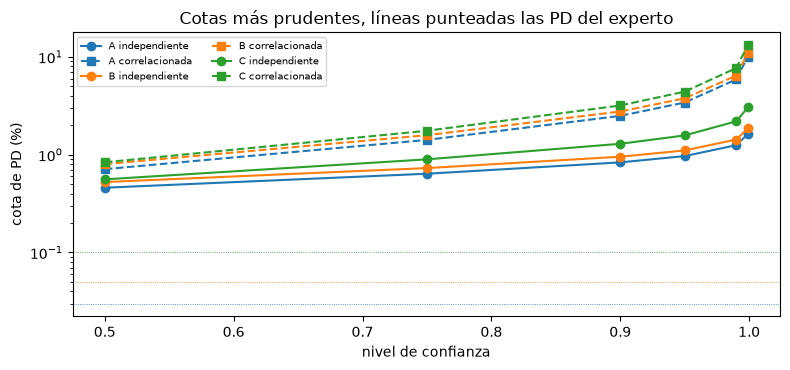

In [10]:
# Dibujar las cotas contra el nivel de confianza, independientes y correlacionadas, con las PD del experto
fig, ax = plt.subplots(figsize=(8, 3.8))
for j, color in enumerate(("tab:blue", "tab:orange", "tab:green")):
    ax.plot(gammas, 100 * independent[:, j], color=color, marker="o", label=f"{grades[j]} independiente")
    ax.plot(gammas, 100 * correlated[:, j], color=color, marker="s", linestyle="--", label=f"{grades[j]} correlacionada")
    ax.axhline(100 * out["expert_pd"][j], color=color, linewidth=0.6, linestyle=":")
ax.set_yscale("log")
ax.set_xlabel("nivel de confianza")
ax.set_ylabel("cota de PD (%)")
ax.set_title("Cotas más prudentes, líneas punteadas las PD del experto")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## Resultados

- **La cota de cada grado descansa en el grupo.** Agrupados desde cada grado hasta el peor, los conteos son 800, 700 y 300 deudores con 3, 3 y 1 incumplimientos; las cotas al 90% son 0,833%, 0,952% y 1,290%. Igualan el cuantil Beta de SciPy y las cotas versionadas a seis niveles, y sin incumplimientos el motor iguala la forma cerrada 1 - (1 - gamma)^(1/N) (0,287%, 0,328% y 0,765% al 90%).
- **La correlación ensancha la cota.** Con la correlación de activos de 12% del artículo las cotas al 90% son 2,49%, 2,76% y 3,18%, cerca de tres veces las independientes para A y B y 2,5 veces para C; al 99,9% la cota del grado A es 10,08%, 6,2 veces su cota independiente.
- **Escalado.** Escaladas a la cota del mejor grado (la propuesta del artículo) las cotas al 90% pasan a 0,652%, 0,745% y 1,010% (K = 0,783); escaladas a la tasa de incumplimiento observada de la cartera de 0,375% pasan a 0,294%, 0,336% y 0,455% (K = 0,352). En ambos casos el promedio ponderado iguala la meta y se mantiene el orden.
- **Años de observación.** Las cotas a cinco años con correlación de activos de 12% y correlación del factor entre años de 30% son menores que las de un año: al 90%, 0,324%, 0,365% y 0,443% frente a 0,833%, 0,952% y 1,290% para el ejemplo, y 0,105%, 0,119% y 0,255% frente a 0,287%, 0,328% y 0,765% sin incumplimientos.
- **Las 204 celdas impresas.** El motor reproduce 129 hasta el dígito impreso. Sesenta difieren en una unidad del último dígito impreso y 15 en más (0,02 a 0,05 puntos en las Tablas 11, 13 y 14, y 0,10 en una celda de la Tabla 12, B al 99,9%: impreso 9,54, recalculado 9,44). Donde difieren lo impreso es mayor en 68 de las 75 celdas; el 0,65% de la Tabla 4 es la cota al 76,3% y no al 75% (0,638%); lo impreso de varios períodos queda sobre el valor Monte Carlo. El recálculo iguala la comparación versionada celda a celda.
- **Lo que dice una verdad conocida.** En el año generado sin incumplimientos la cota independiente del grado C cubre la PD verdadera en cada uno de 20.000 años a todo nivel de 50% a 99%, con una cota mediana de 1,15 veces la verdad al 50% y 7,6 veces al 99%. El grado B al 50% la cubre en el 45,4% de los años (error estándar 0,35 puntos) y la estimación escalada del grado C al 50% en el 46,5%, porque el 53,5% de los años no tiene ningún incumplimiento. Las cotas son conservadoras por construcción y las escaladas renuncian a cobertura.
- **El experto y el capital.** Las PD del experto hipotético son rechazadas por la prueba de Jeffreys para el grado B (p = 0,0047, rojo) y para la cartera (p = 0,0062, rojo), ámbar por la prueba binomial (p = 0,0167) y verde cuando se admite correlación (p = 0,0507). Su ponderador IRB medio es 23,4%, frente a 83,8% con las cotas al 75%, 108,1% con las correlacionadas y 77,2% con las escaladas: el principio de estimación vale decenas de puntos de ponderador de riesgo.

Lo que este cuaderno no muestra: cómo un validador elige un nivel de confianza (el artículo llama arbitraria la elección y dice que niveles bajo 95% parecen más apropiados), ni la curva de PD de una cartera calificada (cuadernos 05 y 09).

## Resumen

- Con pocos o ningún incumplimiento la PD de un grado es una cota superior de confianza sobre el grupo de ese grado y todos los peores; la cota es monótona entre grados y positiva incluso sin incumplimientos.
- La correlación de incumplimientos sube la cota varias veces; escalar a una meta de la cartera la baja y renuncia a leerla como cota; varios años de observación la bajan.
- Las 204 celdas impresas del artículo se recalculan: 129 hasta el dígito, el resto informado con su diferencia y la razón que dan las notas versionadas.
- Una cota es conservadora por construcción: sobre verdad conocida cubre en todo año y es varias veces la PD verdadera.

**Qué probar después.** Cambia el número de incumplimientos del grado A en el Paso 1 de 0 a 1 y mira moverse las tres cotas; luego lee el cuaderno 07.

## Referencias

- Pluto, K. y Tasche, D. (2005), Estimating probabilities of default for low default portfolios, en Engelmann y Rauhmeier (eds), The Basel II Risk Parameters, Springer; arXiv cond-mat/0411699, secciones 2 a 6, Tablas 1 a 14. https://arxiv.org/abs/cond-mat/0411699
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), para las cotas de Clopper-Pearson y de Jeffreys. https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de activos ponderados por riesgo. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162, para el modelo de un factor.